# MATH Level 5 — competition maths (local)

MATH Level 5 (`leaderboard_math_hard`) is the hardest tier of competition maths problems — 1,324 problems, 4-shot, generative. The model must produce the correct final answer.

This notebook runs the benchmark **locally**, straight against the model's chat
endpoint — no EvalHub and no OpenShift. It is self-contained: all settings are in the
configuration cell below, and no job file is needed. It is the notebook equivalent of
the matching `run-*-local.sh` script.

**How it works:** [lm-evaluation-harness](https://github.com/EleutherAI/lm-evaluation-harness)
(`lm_eval`) is run through `uvx`, which fetches it on demand into a throwaway
environment. Questions are sent to the model's `/chat/completions` endpoint with the
model's chat template applied, and answers are scored locally.

**Requires:** [`uv`](https://docs.astral.sh/uv/) (for `uvx`) and network access to the
model endpoint.

## 1. Configuration

Everything you might want to change lives in this one cell.

In [1]:
import json, os, sys, shutil, subprocess
from pathlib import Path

# eval_env.py sits next to the notebooks (the kernel may have started in the parent folder)
sys.path.insert(0, str(next(d for d in (Path("."), Path("notebooks")) if (d / "eval_env.py").is_file())))
from eval_env import setup

# Model endpoint and optional proxy, from .env (or prompts); see eval_env.py
MODEL_URL, MODEL_NAME, MODEL_API_KEY = setup()


# --- Benchmark ---
TASK = "leaderboard_math_hard"  # lm-eval task name
LM_EVAL_VERSION = "0.4.12"  # pinned so results are repeatable
LM_EVAL_EXTRAS = "api,math"  # pip extras lm-eval needs for this task
PYPI_INDEX = "https://pypi.org/simple"  # package index used to install lm-eval, instead of any index set in your uv config
NUM_CONCURRENT = 8          # parallel requests to the model
THRESHOLD = 0.1  # minimum score to count as PASS
MAX_GEN_TOKS = 4096         # max tokens the model may write per answer. The benchmark default (1024) cuts off many
                            # worked solutions before the final answer, scoring them wrong; None keeps that default
LIMIT = None                # e.g. 10 for a quick smoke test; None runs the full benchmark


Loaded settings from .env


## Helper

`run()` launches a command and streams its output into the notebook as it arrives, so you
can watch progress. It raises an error if the command exits non-zero.

In [2]:
def run(cmd, env=None):
    proc = subprocess.Popen(cmd, env={**os.environ, **(env or {})}, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"{cmd[0]} exited with {proc.returncode}")

## 2. Run the benchmark

Builds the `lm_eval` command and runs it. Completed requests are cached on disk, so if
the run dies partway (for example the gateway drops a connection), re-running this cell
resumes where it left off. The cache is deleted after a successful run so the next run
always gets fresh answers from the model.

In [3]:
OUTPUT = Path(f".eval-notebook-{TASK}")             # lm-eval writes results and samples here
CACHE = Path(f".eval-notebook-{TASK}-cache") / "requests"
CACHE.parent.mkdir(exist_ok=True)
shutil.rmtree(OUTPUT, ignore_errors=True)

cmd = ["uvx", "--default-index", PYPI_INDEX, "--python", "3.12", "--from", f"lm-eval[{LM_EVAL_EXTRAS}]=={LM_EVAL_VERSION}",
       "lm_eval", "--model", "local-chat-completions",
       "--model_args", f"model={MODEL_NAME},base_url={MODEL_URL.rstrip('/')}/chat/completions,"
                       f"num_concurrent={NUM_CONCURRENT},max_retries=5,tokenized_requests=False",
       "--tasks", TASK, "--apply_chat_template", "--log_samples",
       "--output_path", str(OUTPUT), "--use_cache", str(CACHE)]
if LIMIT:
    cmd += ["--limit", str(LIMIT)]
if MAX_GEN_TOKS:
    cmd += ["--gen_kwargs", f"max_gen_toks={MAX_GEN_TOKS}"]

# Clear uv index overrides inherited from the environment so lm-eval installs from PYPI_INDEX.
uv_env = {k: "" for k in ("UV_INDEX", "UV_INDEX_URL", "UV_EXTRA_INDEX_URL", "UV_DEFAULT_INDEX")}
run(cmd, env={**uv_env, "OPENAI_API_KEY": MODEL_API_KEY or "not-required"})
shutil.rmtree(CACHE.parent, ignore_errors=True)

Installed 76 packages in 25.27s
Bytecode compiled 8238 files in 25.46s
2026-11-21:17:09:24 INFO     [config.evaluate_config:307] Using default fewshot_as_multiturn=True.
2026-11-21:17:10:07 INFO     [_cli.run:388] Selected Tasks: ['leaderboard_math_hard']
2026-11-21:17:10:07 INFO     [evaluator:214] Setting random seed to 0 | Setting numpy seed to 1234 | Setting torch manual seed to 1234 | Setting fewshot manual seed to 1234
2026-11-21:17:10:07 WARNING  [evaluator:226] generation_kwargs: {'max_gen_toks': 4096} specified through cli, these settings will update set parameters in yaml tasks. Ensure 'do_sample=True' for non-greedy decoding!
2026-11-21:17:10:07 INFO     [evaluator:239] Initializing local-chat-completions model, with arguments: {'model': 'gemma-4', 'base_url': 'https://maas.apps.ocp.home.glroland.com/sandbox/gemma-4/v1/chat/completions', 'num_concurrent': 8, 'max_retries': 5, 'tokenized_requests': False}
2026-11-21:17:10:07 INFO     [models.api_models:179] Using max length 2

## 3. Score and pass/fail

The score is `exact_match` on the final answer, averaged over the maths subjects. Scores are low even for strong models, hence the low threshold. Per-question model answers are in the `.eval-notebook-<task>` folder (`samples_*.jsonl`) if you want to see what it got wrong.

In [4]:
results_file = next(OUTPUT.rglob("results_*.json"))
scores = json.loads(results_file.read_text())["results"][TASK]

# The group-level exact_match is the overall score across all subjects.
score = next(v for k, v in scores.items() if k.startswith("exact_match,"))
print(f"exact_match: {score:.3f}")
print("PASS" if score >= THRESHOLD else "FAIL", f"- exact_match {score:.3f} vs threshold {THRESHOLD}")

exact_match: 0.894
PASS - exact_match 0.894 vs threshold 0.1


## 4. Results dashboard

Accuracy by subject with 95% confidence intervals, how outcomes change with solution length, and — importantly — *why* problems were missed: a wrong final answer, or a solution that ran out of tokens before reaching one. Those two call for very different fixes.

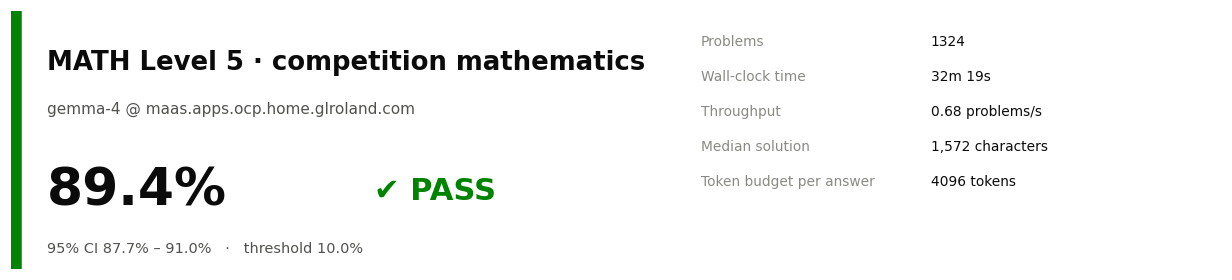

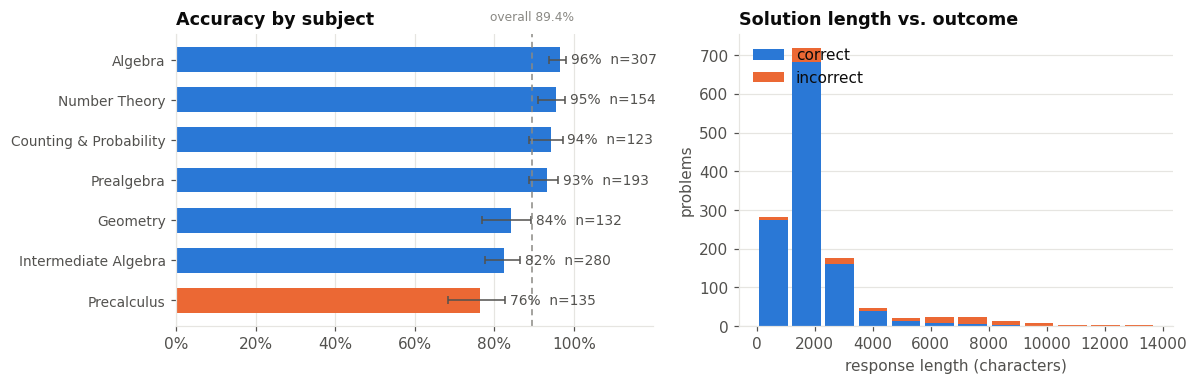

Accuracy by solution length (quartiles of response length):
  shortest 25%   97.6%   (428–1,196 chars)
  25–50%         96.1%   (1,196–1,571 chars)
  50–75%         93.7%   (1,573–2,260 chars)
  longest 25%    70.4%   (2,261–13,740 chars)
  → long solutions are usually harder problems; if the longest bucket also sits at the 4096-token budget, raise it before blaming the model.

140 of 1324 problems missed:
  • 68 gave a final answer that was wrong
  • 72 never reached a final answer — the solution was still working when it stopped (budget: 4096 tokens)
  When it did finish, accuracy was 94.6% (1184/1252); a larger token budget could lift the headline toward that.

A sample of misses (expected answer vs. the end of the model's working):

  ✘ [Algebra · wrong answer] Find all positive integer values of $c$ such that the equation $x^2-7x+c=0$ only has roots that are real and rational. Express them in decreasing ord…
      expected: 12, 10, 6
      model ended: …a perfect square are $6, 10

In [5]:
import sys
from pathlib import Path
# eval_report.py sits next to the notebooks (the kernel may have started in the parent folder)
sys.path.insert(0, str(next(d for d in (Path("."), Path("notebooks")) if (d / "eval_report.py").is_file())))
from eval_report import report_math

report_math(OUTPUT, THRESHOLD)